In [1]:
import xarray as xr
import numpy as np
import xesmf as xe
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from regional_mom6 import regridding as rgd
from regridding_analysis import *

In [2]:
directions = ["north", "south", "east"]
weights = {}
raw_ds = {}
regridded_ds = {}
coords = {}
for direction in directions:
    weights[direction] = xr.open_dataset(f"/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_interpolated_data/{direction}_weights.nc")
    raw_ds[direction] = xr.open_dataset(f"/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/raw_interpolated_data/DIC_{direction}_vfilled.nc")
    regridded_ds[direction] = xr.open_dataset(f"/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_interpolated_data/DIC_{direction}_regridded.nc")

hgrid = xr.open_dataset("/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_hgrid.nc")

coords["north"] = rgd.coords(hgrid, "north", "segment_002")
coords["south"] = rgd.coords(hgrid, "south", "segment_001")
coords["east"] = rgd.coords(hgrid, "east", "segment_003")
# Access variables
cols = {}
rows = {}
weights_vals = {}
flat_tlon = {}
flat_tlat = {}
for direction in directions:
    cols[direction] = weights[direction].col.values
    rows[direction] = weights[direction].row.values
    weights_vals[direction] = weights[direction].S.values
    flat_tlon[direction] = raw_ds[direction]['TLONG'].values.flatten()
    flat_tlat[direction] = raw_ds[direction]['TLAT'].values.flatten()


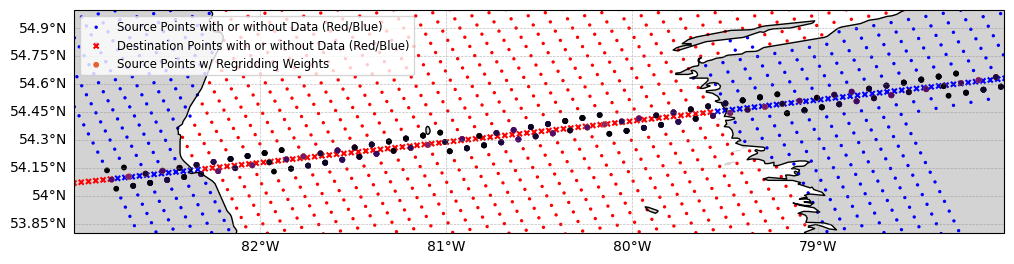

In [ ]:
# Plot
direction = "north"

source_points_used_lon = flat_tlon[direction][cols[direction]-1]
source_points_used_lat = flat_tlat[direction][cols[direction]-1]

lons_raw = np.where(np.isfinite(raw_ds[direction].TLONG), raw_ds[direction].TLONG, -100)
lats_raw = np.where(np.isfinite(raw_ds[direction].TLAT), raw_ds[direction].TLAT, 65)

fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.PlateCarree())
#ax.set_extent([-100,-35,40,60])
#ax.set_extent([-63,-61,55,57], crs=ccrs.PlateCarree())
ax.set_extent([-83,-78,53.8,55], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, fc="lightgray")
ax.coastlines(resolution="10m")
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = gl.right_labels = False



# Plot Raw Vals
ax.scatter(lons_raw, lats_raw, c=~np.isnan(raw_ds[direction].DIC[0,0]),cmap ="bwr",s = 2, label = "Source Points with or without Data (Red/Blue)", transform=ccrs.PlateCarree())

# Plot regridded vals
ax.scatter(coords[direction].lon,coords[direction].lat,c = ~np.isnan(regridded_ds[direction].__xarray_dataarray_variable__[0,0]), s=13, marker='x',cmap = "bwr", label = "Destination Points with or without Data (Red/Blue)", transform=ccrs.PlateCarree())

#Plot source points for bilinear regridding
sc = ax.scatter(source_points_used_lon, source_points_used_lat, c=weights[direction].S, cmap='inferno', s=10, transform=ccrs.PlateCarree(), label = "Source Points w/ Regridding Weights")

# Plot the scatter regridded
ax.legend(loc="upper left", fontsize="small")

plt.show()

In [4]:
regridded_ds[direction]

<xarray.Dataset>
Dimensions:                        (z_t: 62, time: 12, nx_segment_002: 1481)
Coordinates:
  * z_t                            (z_t) float32 500.0 1.5e+03 ... 5.875e+05
  * time                           (time) object 2000-02-01 00:00:00 ... 2001...
    lon                            (nx_segment_002) float64 ...
    lat                            (nx_segment_002) float64 ...
Dimensions without coordinates: nx_segment_002
Data variables:
    __xarray_dataarray_variable__  (time, z_t, nx_segment_002) float32 ...

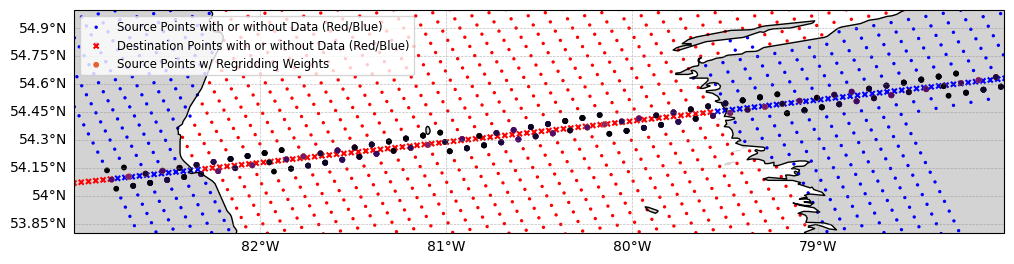

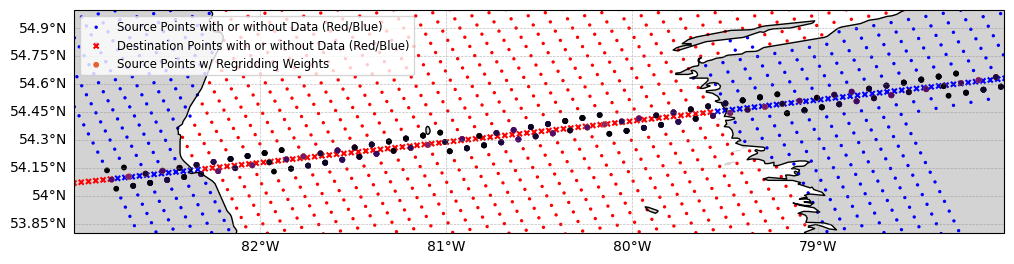

In [3]:

plot_regridding_snapshot(raw_ds["north"], regridded_ds["north"], weights["north"], raw_var_name = "DIC", regrid_var_name="__xarray_dataarray_variable__")

All Nans in source point with index: <xarray.DataArray 'col' ()>
array(58785)
All Nans in source point with index: <xarray.DataArray 'col' ()>
array(58786)
All Nans in source point with index: <xarray.DataArray 'col' ()>
array(59274)
All Nans in source point with index: <xarray.DataArray 'col' ()>
array(59275)
Point Index: 415 Latitude: 54.0986800231896 Longitude: -82.727219751951 is:  nan from #Nans in Source Point Values: 4
All Nans in source point with index: <xarray.DataArray 'col' ()>
array(58296)
All Nans in source point with index: <xarray.DataArray 'col' ()>
array(58297)
All Nans in source point with index: <xarray.DataArray 'col' ()>
array(58785)
All Nans in source point with index: <xarray.DataArray 'col' ()>
array(58786)
Point Index: 416 Latitude: 54.10294059215155 Longitude: -82.68804002514207 is:  nan from #Nans in Source Point Values: 4
All Nans in source point with index: <xarray.DataArray 'col' ()>
array(58297)
All Nans in source point with index: <xarray.DataArray 'col

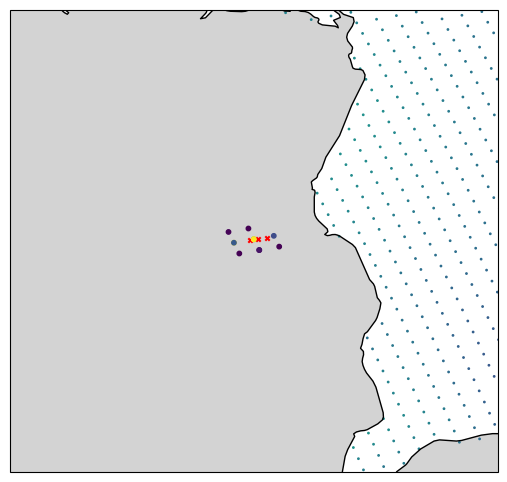

In [ ]:
direction = "north"
point_indexes = np.arange(415,418,1)
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, fc="lightgray")
ax.coastlines(resolution="10m")
min_lon = 1000
max_lon = -1000
min_lat = 1000
max_lat = -1000
for point_index in point_indexes:
    indexes = np.where(weights[direction].row == point_index)
    source_indexes = weights[direction].col[indexes]
    if len(source_indexes) == 0:
        #print(f"Point index {point_index} not found in weights.")
        continue
    source_points_used_lon = flat_tlon[direction][source_indexes-1]
    source_points_used_lat = flat_tlat[direction][source_indexes-1]
    if source_points_used_lon.min()< min_lon: 
        min_lon = source_points_used_lon.min()
    if source_points_used_lon.max() > max_lon:
        max_lon = source_points_used_lon.max()
    if source_points_used_lat.min() < min_lat:
        min_lat = source_points_used_lat.min()
    if source_points_used_lat.max() > max_lat:
        max_lat = source_points_used_lat.max()
    
    sc = ax.scatter(source_points_used_lon, source_points_used_lat, c=weights[direction].S[indexes], s=10, transform=ccrs.PlateCarree())
    source_point_vals = raw_ds[direction].DIC[0,0].values.flatten()[source_indexes]      
    dest_point_vals = regridded_ds[direction].__xarray_dataarray_variable__[0,0].values[point_index]
    print("Point Index:", point_index, "Latitude:", coords[direction].lat[point_index].values, "Longitude:", coords[direction].lon[point_index].values, "is: ", dest_point_vals, "from #Nans in Source Point Values:", len(np.where(np.isnan(source_point_vals))[0]))
    dest = ax.scatter(coords[direction].lon[point_index], coords[direction].lat[point_index].values, c='red', s=10, transform=ccrs.PlateCarree(), marker = "x")
source_points_used_lon = np.where(np.isfinite(raw_ds[direction].TLONG), raw_ds[direction].TLONG, 30)
source_points_used_lat = np.where(np.isfinite(raw_ds[direction].TLAT), raw_ds[direction].TLAT, -90)
ax.scatter(source_points_used_lon, source_points_used_lat, c=raw_ds[direction].DIC[0,0], cmap='viridis', s= 1)
ax.set_extent([min_lon-1,max_lon+1,min_lat-1,max_lat+1], crs=ccrs.PlateCarree())
plt.show()


# From here, we can check, of the points that got weighted, (some destination did't), we can check was there a value in the answer, and the amount of Nans in the source points

Point Index: 430 Latitude: 54.16295861091795 Longitude: -82.13910920260378 is:  1976.1132 from #Nans in Source Point Values: 0


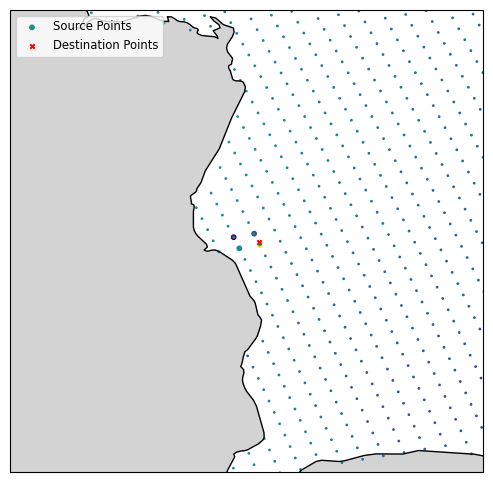

In [4]:

regridding_point_analysis(raw_ds["north"], regridded_ds["north"], weights["north"],[430], raw_var_name = "DIC", regrid_var_name="__xarray_dataarray_variable__")

In [5]:
ocean_static = xr.open_dataset("/glade/derecho/scratch/manishrv/angle_calc.2.2n3b/run/run_200/ocean_static.nc")





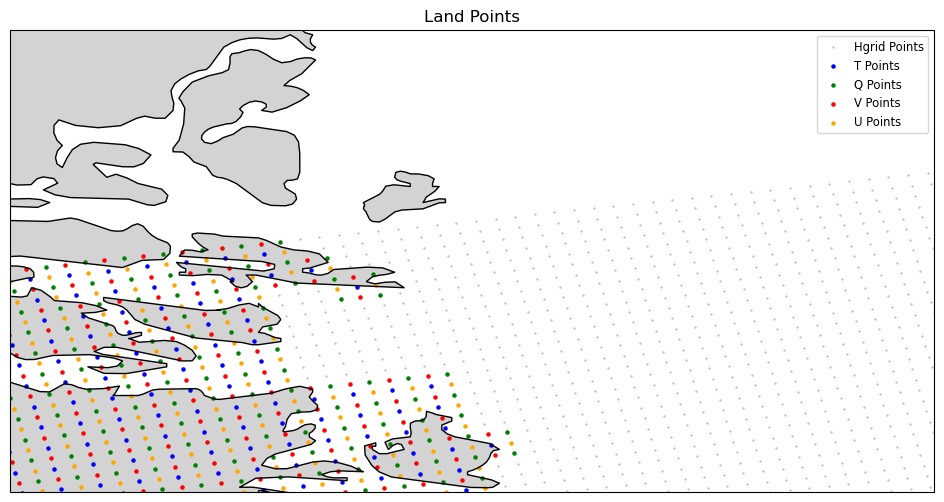

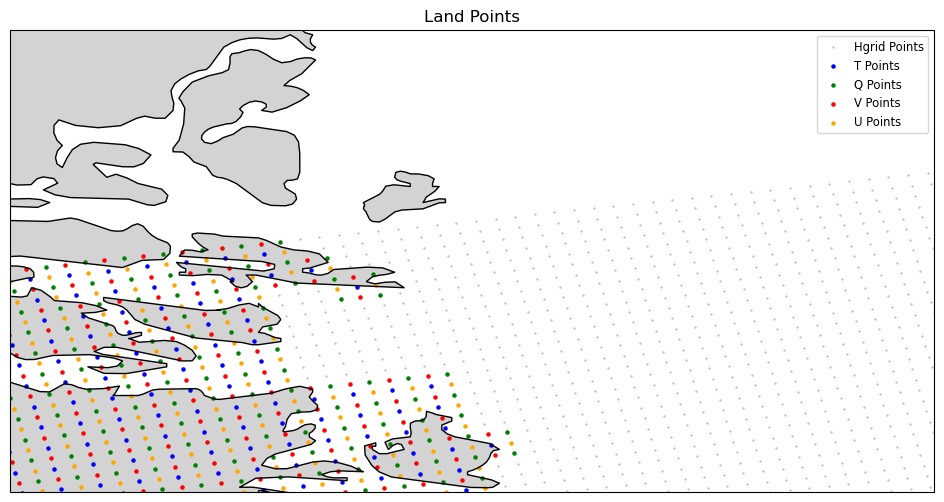

In [6]:

plot_region_mask(ocean_static, hgrid)

    

In [ ]:
# Subset to roughly the north

t_points = rgd.get_hgrid_arakawa_c_points(hgrid, "t")
v_points = rgd.get_hgrid_arakawa_c_points(hgrid, "v")
u_points = rgd.get_hgrid_arakawa_c_points(hgrid, "u")
q_points = rgd.get_hgrid_arakawa_c_points(hgrid, "q")
ocean_static["tlon"] = (("yh","xh"),(t_points.tlon.values))
ocean_static["tlat"] = (("yh","xh"),(t_points.tlat.values))
ocean_static["ulon"] = (("yh","xq"),(u_points.ulon.values))
ocean_static["ulat"] = (("yh","xq"),(u_points.ulat.values))
ocean_static["qlon"] = (("yq","xq"),(q_points.qlon.values))
ocean_static["qlat"] = (("yq","xq"),(q_points.qlat.values))
ocean_static["vlon"] = (("yq","xh"),(v_points.vlon.values))
ocean_static["vlat"] = (("yq","xh"),(v_points.vlat.values))

In [37]:
filter_mask_t = ocean_static["wet"] == 0
filter_mask_c = ocean_static["wet_c"] == 0
filter_mask_v = ocean_static["wet_v"] == 0
filter_mask_u = ocean_static["wet_u"] == 0

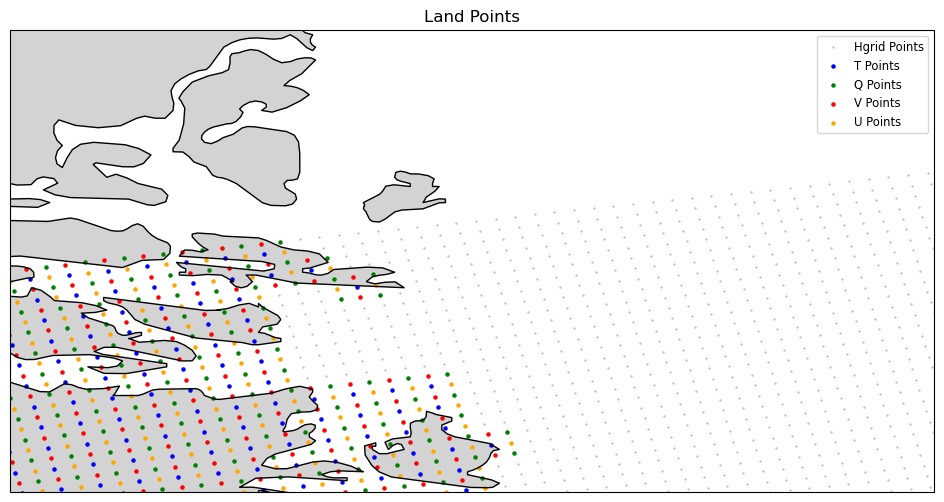

In [ ]:
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, fc="lightgray")
ax.coastlines(resolution="10m")
ax.set_extent([-62,-60,56,57], crs=ccrs.PlateCarree())
ax.scatter(hgrid.x, hgrid.y, c="gray", s=0.1, transform=ccrs.PlateCarree(), label="Hgrid Points")

ax.scatter(ocean_static.tlon.values[filter_mask_t], ocean_static.tlat.values[filter_mask_t], c="blue", s=5, transform=ccrs.PlateCarree(), label="T Points")
ax.scatter(ocean_static.qlon.values[filter_mask_c], ocean_static.qlat.values[filter_mask_c], c="green", s=5, transform=ccrs.PlateCarree(), label="Q Points")
ax.scatter(ocean_static.vlon.values[filter_mask_v], ocean_static.vlat.values[filter_mask_v], c="red", s=5, transform=ccrs.PlateCarree(), label="V Points")
ax.scatter(ocean_static.ulon.values[filter_mask_u], ocean_static.ulat.values[filter_mask_u], c="orange", s=5, transform=ccrs.PlateCarree(), label="U Points")

ax.legend(loc="upper right", fontsize="small")
ax.set_title("Land Points")
plt.show()

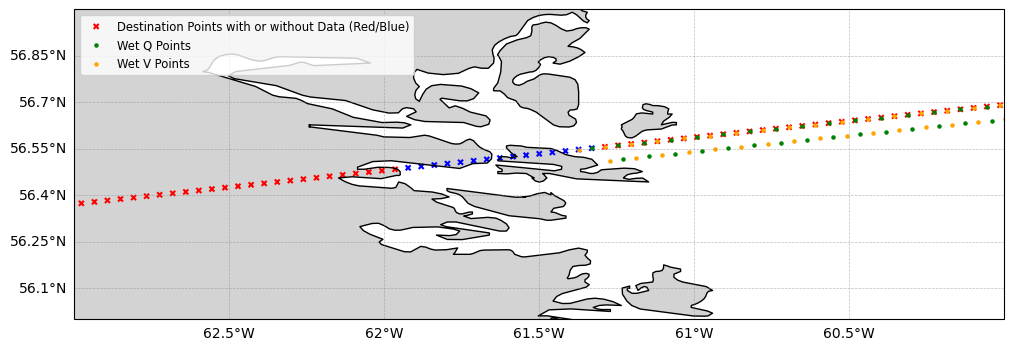

In [ ]:
# Plot
direction = "north"
ocean_static = ocean_static.isel(yq=[-1,-2],yh=[-1,-2])
filter_mask_t = ocean_static["wet"] == 0
filter_mask_c = ocean_static["wet_c"] == 0
filter_mask_v = ocean_static["wet_v"] == 0
filter_mask_u = ocean_static["wet_u"] == 0
source_points_used_lon = flat_tlon[direction][cols[direction]-1]
source_points_used_lat = flat_tlat[direction][cols[direction]-1]

lons_raw = np.where(np.isfinite(raw_ds[direction].TLONG), raw_ds[direction].TLONG, -100)
lats_raw = np.where(np.isfinite(raw_ds[direction].TLAT), raw_ds[direction].TLAT, 65)

fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.PlateCarree())
#ax.set_extent([-100,-35,40,60])
#ax.set_extent([-63,-61,55,57], crs=ccrs.PlateCarree())
ax.set_extent([-63,-60,56,57], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, fc="lightgray")
ax.coastlines(resolution="10m")
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = gl.right_labels = False



# Plot Raw Vals
#ax.scatter(lons_raw, lats_raw, c=~np.isnan(raw_ds[direction].DIC[0,0]),cmap ="bwr",s = 2, label = "Source Points with or without Data (Red/Blue)", transform=ccrs.PlateCarree())

# Plot regridded vals
ax.scatter(coords[direction].lon,coords[direction].lat,c = ~np.isnan(regridded_ds[direction].__xarray_dataarray_variable__[0,0]), s=13, marker='x',cmap = "bwr", label = "Destination Points with or without Data (Red/Blue)", transform=ccrs.PlateCarree())

#Plot source points for bilinear regridding
#sc = ax.scatter(lons_dest, lats_dest, c=weights[direction].S, cmap='inferno', s=10, transform=ccrs.PlateCarree(), label = "Source Points w/ Regridding Weights")
ax.scatter(ocean_static.qlon.values[~filter_mask_c], ocean_static.qlat.values[~filter_mask_c], c="green", s=5, transform=ccrs.PlateCarree(), label="Wet Q Points")
ax.scatter(ocean_static.vlon.values[~filter_mask_v], ocean_static.vlat.values[~filter_mask_v], c="orange", s=5, transform=ccrs.PlateCarree(), label="Wet V Points")

# Plot the scatter regridded
ax.legend(loc="upper left", fontsize="small")

plt.show()


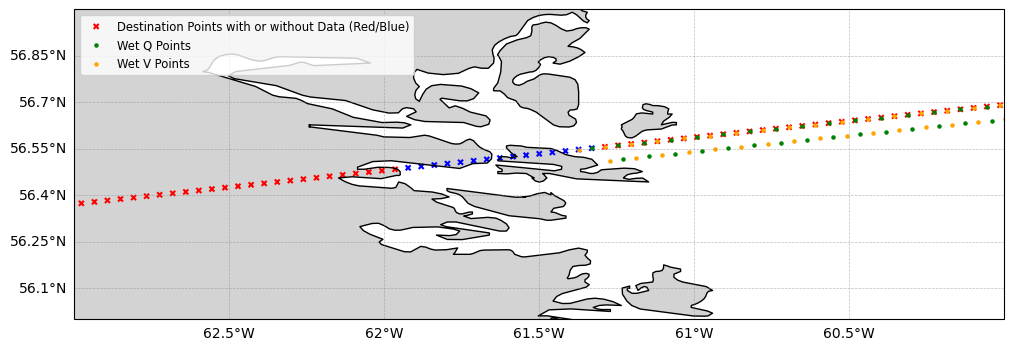

In [ ]:


plot_boundary_mask(ocean_static, hgrid, regridded_ds["north"],regrid_var_name="__xarray_dataarray_variable__")

In [28]:
regridded_ds

{'north': <xarray.Dataset>
 Dimensions:                        (z_t: 62, time: 12, nx_segment_002: 1481)
 Coordinates:
   * z_t                            (z_t) float32 500.0 1.5e+03 ... 5.875e+05
   * time                           (time) object 2000-02-01 00:00:00 ... 2001...
     lon                            (nx_segment_002) float64 -98.75 ... -37.45
     lat                            (nx_segment_002) float64 52.78 ... 58.38
 Dimensions without coordinates: nx_segment_002
 Data variables:
     __xarray_dataarray_variable__  (time, z_t, nx_segment_002) float32 ...,
 'south': <xarray.Dataset>
 Dimensions:                        (z_t: 62, time: 12, nx_segment_001: 1481)
 Coordinates:
   * z_t                            (z_t) float32 500.0 1.5e+03 ... 5.875e+05
   * time                           (time) object 2000-02-01 00:00:00 ... 2001...
     lon                            (nx_segment_001) float64 ...
     lat                            (nx_segment_001) float64 ...
 Dimensions wi

# Summary
if the source points have any nans, anywhere in the bilinear interpolation (on the surface) the destination point is Nan
How does this change with depth? And why is it that the regridding returns zero, where there is no weight? How does that work?
Depth levels are not regridded independently, and it seems like regridding returns zeros wherever there isn't weight.

# next work
figure out the horizontal masks (land mask) between the two and figure out the vertical mask (bathymetry) between the two

In [74]:
# Find Nans
np.where(np.isnan(regridded_ds.__xarray_dataarray_variable__[0,0]))

(array([414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 496,
        497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509,
        510, 511, 512, 513, 514, 515, 516, 517, 518, 519, 520, 521, 522,
        523, 524, 525, 526, 527, 528, 529, 530, 531, 532, 533, 534, 535,
        536, 537, 538, 539, 540, 541, 542, 543, 544, 545, 546, 547, 548,
        549, 550, 551, 552, 553, 554, 555, 928, 929, 930, 931, 932, 933,
        934, 935, 936, 937, 938, 939, 940, 941, 942]),)

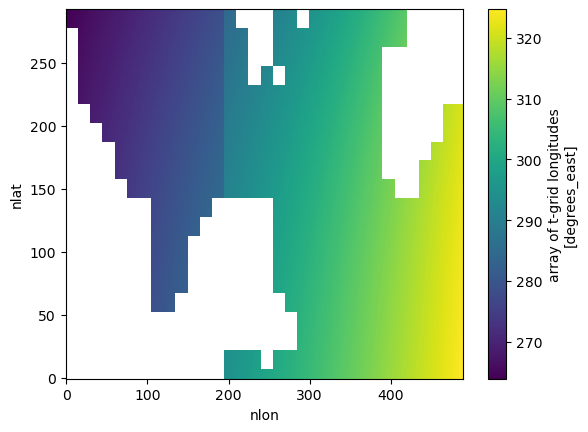

In [20]:
raw_ds["north"].TLONG.plot()

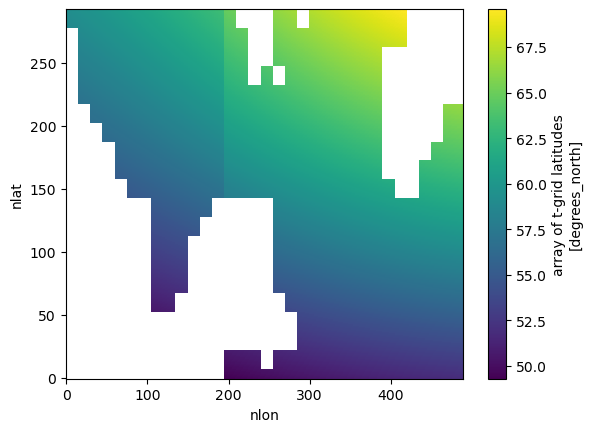

In [21]:
raw_ds["north"].TLAT.plot()

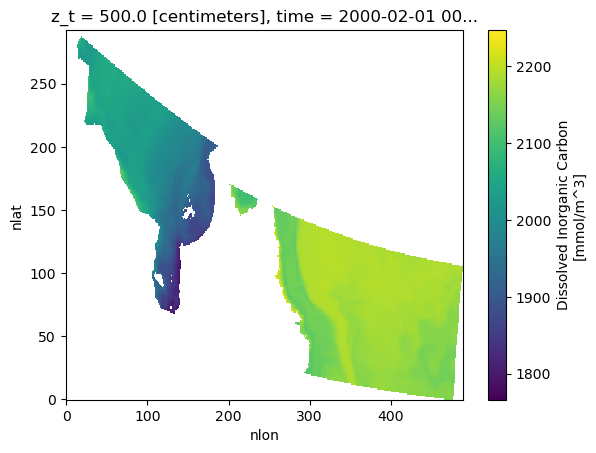

In [3]:
raw_ds["north"].DIC[0,0].plot()